In [ ]:
!pip install geopandas
!pip install descartes
!pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
from google.colab import drive
import os

In [ ]:
# Manipulação e carregamento de dados
import geopandas as gpd
import pandas as pd
import numpy as np

# Plotagem de dados e resultados
import matplotlib.pyplot as plt
import seaborn as sns

# Aprendizado de Máquina
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# 1. Montar o Google Drive (se já estiver montado, ele apenas avisa)
drive.mount('/content/drive', force_remount=True)

# 2. Definir o caminho exato da pasta Vetores no seu Drive
# O Colab acessa o Meu Drive através da pasta '/content/drive/MyDrive/'
caminho_vetores = '/content/drive/MyDrive/POLI+pessoal/Curso de Férias/Projeto Final/Vetores'
caminho_dataprod = '/content/drive/MyDrive/POLI+pessoal/Curso de Férias/Projeto Final/Tratamento Preliminar'

# 3. Construir os caminhos para os arquivos .shp
# (Lembre-se de ajustar os nomes 'Siririzinho.shp' e 'POCOS.shp' se os nomes reais dentro da pasta forem diferentes)
path_campo = os.path.join(caminho_vetores, 'SIRIRIZINHO-zip', 'campos_gishub_db.shp')
path_pocos = os.path.join(caminho_vetores, 'SIRIRIZINHO_pocos-zip', 'pocos_gishub_db.shp')
path_prod = os.path.join(caminho_dataprod, 'ATUALIZADO_CONSOLIDADO_GERAL.csv')

# Se as pastas no seu Drive estiverem soltas (sem subpastas com o nome '-zip'), use assim:
# path_campo = os.path.join(caminho_vetores, 'Siririzinho.shp')
# path_pocos = os.path.join(caminho_vetores, 'POCOS.shp')

# 4. Carregar os arquivos com o Geopandas
campo = gpd.read_file(path_campo)
pocos = gpd.read_file(path_pocos)

# Carregar prod: Ler todas as colunas como strings inicialmente
# e depois converter as colunas numéricas manualmente para garantir o separador decimal.
prod = pd.read_csv(path_prod, decimal = ',', sep=';', thousands ='.', encoding='latin-1')

display(len(prod['Nome Poço ANP'].unique()))
display(len(pocos['name'].unique()))
display(prod)

print("Arquivos carregados com sucesso do Google Drive!")

Mounted at /content/drive


241

661

,Nome Poço ANP,O_bpd_2026_01,GN_Mcm_2026_01,A_bpd_2026_01,O_bpd_2026_02,GN_Mcm_2026_02,A_bpd_2026_02,O_bpd_2026_03,GN_Mcm_2026_03,A_bpd_2026_03,...,A_bpd_2023_09,O_bpd_2023_10,GN_Mcm_2023_10,A_bpd_2023_10,O_bpd_2023_11,GN_Mcm_2023_11,A_bpd_2023_11,O_bpd_2023_12,GN_Mcm_2023_12,A_bpd_2023_12
0,1-SZ-1-SE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3-BRSA-1093-SE,7.5267,0.0348,58.6831,7.4379,0.0364,58.4380,5.7860,0.0231,41.3908,...,NaN,NaN,NaN,NaN,12.1135,0.0647,52.1572,12.4421,0.0529,50.2221
2,3-BRSA-794-SE,1.9829,0.0094,66.3157,4.5671,0.0221,229.9301,3.3490,0.0134,217.3856,...,343.1989,21.1496,0.0655,298.0575,22.3949,0.1220,289.5655,23.3356,0.0992,289.5514
3,3-BRSA-932-SE,4.3256,0.0201,0.1094,5.5040,0.0269,0.1402,6.4235,0.0257,0.1491,...,0.0019,0.0276,0.0001,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
4,3-BRSA-972D-SE,1.2513,0.0058,2.7180,1.4527,0.0070,5.2363,1.3247,0.0055,12.1312,...,5.0444,12.6936,0.0000,11.1977,12.9595,0.0405,11.0300,12.0458,0.0578,10.4228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
236,8-SZ-434-SE,4.9215,0.0230,80.8831,6.8889,0.0336,80.7886,7.1128,0.0285,75.9503,...,133.2861,8.6103,0.0415,136.8482,9.3469,0.0644,138.6046,9.0411,0.0381,132.0740
237,8-SZ-442D-SE,22.0354,0.1026,535.2117,19.6781,0.0959,481.6471,20.5646,0.0826,415.0749,...,350.0705,17.9663,0.0685,399.3317,14.4181,0.0815,438.5151,10.3745,0.0441,416.9274
238,8-SZ-451D-SE,12.1633,0.0566,208.2938,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
239,8-SZ-457-SE,23.5523,0.1088,443.3257,15.8737,0.0775,473.1352,16.3458,0.0655,443.6089,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.8543,0.0636,263.0563


Arquivos carregados com sucesso do Google Drive!


In [ ]:
# 1. Garantir que ambos os shapefiles estão no mesmo sistema de coordenadas (CRS)
if pocos.crs != campo.crs:
    pocos = pocos.to_crs(campo.crs)

# 2. FILTRO ESPACIAL: Mantém apenas os poços cujos pontos estão DENTRO do polígono do campo 'Siririzinho'
# O 'predicate="intersects"' (ou 'within') garante que pegamos apenas os poços de dentro da área
pocos_no_campo = gpd.sjoin(pocos, campo, how="inner", predicate="intersects")
display(pocos_no_campo.head())

,feicao_id_left,name_left,operador_left,titularida,categoria,tipo_grupo,tipo,cadastro,sigla_esta,nome_bacia_left,...,sigla,dat_descob,dat_inicio_right,etapa,fluido_pri,med_lamina,name_right,code,creation_d_right,modificati_right
0,3684144.0,8-SZ-392-SE,Petrobras,Público,Injeção,producao,Explotatório,90120020043,SE,Sergipe,...,SZ,20-10-1967,30-11-1967,Produção,ÓLEO,0,SIRIRIZINHO,288,2026-07-10,2026-07-10
1,3684147.0,7-SZ-423DP-SE,Petrobras,Público,Desenvolvimento,producao,Explotatório,90120020468,SE,Sergipe,...,SZ,20-10-1967,30-11-1967,Produção,ÓLEO,0,SIRIRIZINHO,288,2026-07-10,2026-07-10
2,3700908.0,7-SZ-541D-SE,Petrobras,Público,Desenvolvimento,producao,Explotatório,90120027371,SE,Sergipe,...,SZ,20-10-1967,30-11-1967,Produção,ÓLEO,0,SIRIRIZINHO,288,2026-07-10,2026-07-10
3,3697327.0,8-SZ-178-SE,Petrobras,Público,Injeção,producao,Explotatório,901200144600,SE,Sergipe,...,SZ,20-10-1967,30-11-1967,Produção,ÓLEO,0,SIRIRIZINHO,288,2026-07-10,2026-07-10
4,3709922.0,7-SZ-650D-SE,Carmo,Público,Desenvolvimento,producao,Explotatório,90120030178,SE,Sergipe,...,SZ,20-10-1967,30-11-1967,Produção,ÓLEO,0,SIRIRIZINHO,288,2026-07-10,2026-07-10


In [ ]:
# 1. Supondo que 'df_final' ou seu arquivo consolidado já esteja carregado na variável 'prod'
# (Se precisar ler o arquivo salvo do zero, use: prod = pd.read_csv("ATUALIZADO_CONSOLIDADO_GERAL.csv", sep=';', encoding='latin-1'))

# 2. Definir o limite para eliminar linhas 70% vazias.
# Se a tabela tem X colunas de meses, calculamos 70% de dados nulos permitidos.
limite_nulos = int(len(prod.columns) * 0.7)

# Remove linhas que tenham 70% ou mais de valores nulos (dropna com thresh)
# 'thresh' define o número mínimo de valores NÃO NULOS que a linha precisa ter para ser mantida.
colunas_de_dados = len(prod.columns) - 1 # Descontando a coluna 'Nome Poço ANP'
min_valores_validos = colunas_de_dados - limite_nulos

prod_limpo = prod.dropna(thresh=min_valores_validos + 1) # +1 para contar a coluna do poço

print(f"Poços antes da limpeza: {len(prod)}")
print(f"Poços após remover os 70% vazios: {len(prod_limpo)}")

display(prod_limpo.head())

Poços antes da limpeza: 241
Poços após remover os 70% vazios: 197


,Nome Poço ANP,O_bpd_2026_01,GN_Mcm_2026_01,A_bpd_2026_01,O_bpd_2026_02,GN_Mcm_2026_02,A_bpd_2026_02,O_bpd_2026_03,GN_Mcm_2026_03,A_bpd_2026_03,...,A_bpd_2023_09,O_bpd_2023_10,GN_Mcm_2023_10,A_bpd_2023_10,O_bpd_2023_11,GN_Mcm_2023_11,A_bpd_2023_11,O_bpd_2023_12,GN_Mcm_2023_12,A_bpd_2023_12
1,3-BRSA-1093-SE,7.5267,0.0348,58.6831,7.4379,0.0364,58.4380,5.7860,0.0231,41.3908,...,NaN,NaN,NaN,NaN,12.1135,0.0647,52.1572,12.4421,0.0529,50.2221
2,3-BRSA-794-SE,1.9829,0.0094,66.3157,4.5671,0.0221,229.9301,3.3490,0.0134,217.3856,...,343.1989,21.1496,0.0655,298.0575,22.3949,0.1220,289.5655,23.3356,0.0992,289.5514
3,3-BRSA-932-SE,4.3256,0.0201,0.1094,5.5040,0.0269,0.1402,6.4235,0.0257,0.1491,...,0.0019,0.0276,0.0001,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
4,3-BRSA-972D-SE,1.2513,0.0058,2.7180,1.4527,0.0070,5.2363,1.3247,0.0055,12.1312,...,5.0444,12.6936,0.0000,11.1977,12.9595,0.0405,11.0300,12.0458,0.0578,10.4228
5,3-SZ-13-SE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,13.0247,2.1398,0.0109,11.6471,1.9243,0.0114,9.5884,2.2897,0.0097,10.9339


In [ ]:

# Nota: O sjoin pode duplicar colunas de ID se houver sobreposição de nomes.
# Vamos garantir que estamos usando a coluna 'name' correta dos poços.
# (Se a coluna de nome do poço no seu shapefile for 'POCO' ou 'name', ajuste abaixo se necessário)

# 3. FILTRO DE PRODUÇÃO: Agora aplicamos o seu filtro anterior para manter
# apenas os poços que estão dentro do campo E que também estão presentes em 'prod' (com dados válidos)
pocos_prod = pocos_no_campo[pocos_no_campo['name_left'].isin(prod_limpo['Nome Poço ANP'])].copy()

print(f"Poços totais no shapefile: {len(pocos)}")
print(f"Poços dentro do polígono do campo: {len(pocos_no_campo)}")
print(f"Poços finais (dentro do campo + produtores válidos): {len(pocos_prod)}")

Poços totais no shapefile: 661
Poços dentro do polígono do campo: 654
Poços finais (dentro do campo + produtores válidos): 196


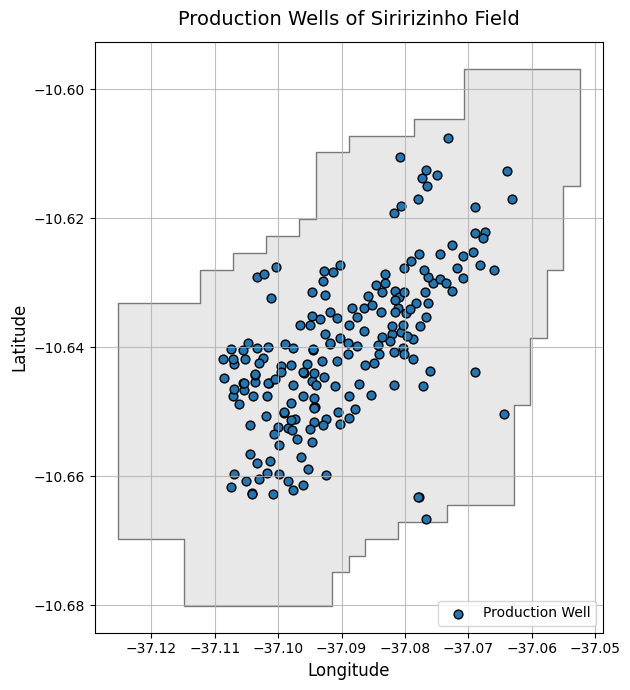

In [ ]:
# 5. Plotagem dos dados no mapa
ax = campo.plot(figsize=(7*16/9, 7), zorder=0, color="lightgray", edgecolor="black", alpha=0.5)
pocos_prod.plot(ax=ax, figsize=(7, 7), zorder=1, markersize=40, label ='Production Well', edgecolor = 'black')

plt.title("Production Wells of Siririzinho Field", fontsize = 14, pad = 12)
plt.xlabel("Longitude", fontsize = 12)
plt.ylabel("Latitude", fontsize = 12)
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.8)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Separar as colunas de dados mensais por tipo de fluido com base nos prefixos
colunas_oleo = [col for col in prod_limpo.columns if col.startswith('O_bpd_')]
colunas_gas = [col for col in prod_limpo.columns if col.startswith('GN_Mcm_')]
colunas_agua = [col for col in prod_limpo.columns if col.startswith('A_bpd_')]

# 2. Fazer o melt para cada conjunto de colunas, mantendo 'Nome Poço ANP'
df_oleo = prod_limpo.melt(
    id_vars=['Nome Poço ANP'],
    value_vars=colunas_oleo,
    var_name='Data_Arquivo',
    value_name='Petroleo_bpd'
)

df_gas = prod_limpo.melt(
    id_vars=['Nome Poço ANP'],
    value_vars=colunas_gas,
    var_name='Data_Arquivo',
    value_name='Gas_Mcm_dia'
)

df_agua = prod_limpo.melt(
    id_vars=['Nome Poço ANP'],
    value_vars=colunas_agua,
    var_name='Data_Arquivo',
    value_name='Agua_bpd'
)

# 3. Mesclar os dataframes resultantes utilizando o Poço e a Data como chave
# Como a coluna 'Data_Arquivo' gerada em cada melt guarda o sufixo original (ex: 'O_bpd_2026_01'),
# precisamos padronizar ou fazer o merge alinhando pelas posições/chaves compostas.
# Uma forma mais direta e robusta no Pandas é usar pd.wide_to_long ou mesclar limpando a string da data:

df_oleo['Data'] = df_oleo['Data_Arquivo'].str.replace('O_bpd_', '')
df_gas['Data'] = df_gas['Data_Arquivo'].str.replace('GN_Mcm_', '')
df_agua['Data'] = df_agua['Data_Arquivo'].str.replace('A_bpd_', '')

# Unificando tudo em um único dataframe longo final
df_melted = df_oleo[['Nome Poço ANP', 'Data', 'Petroleo_bpd']].copy()
df_melted['Gas_Mcm_dia'] = df_gas['Gas_Mcm_dia']
df_melted['Agua_bpd'] = df_agua['Agua_bpd']

# Ordenar para melhor visualización
df_melted = df_melted.sort_values(by=['Nome Poço ANP', 'Data']).reset_index(drop=True)
df_melted.describe()

,Petroleo_bpd,Gas_Mcm_dia,Agua_bpd
count,6196.000000,6196.000000,6196.000000
mean,9.852764,0.043241,162.249385
std,10.238982,0.049983,178.989874
min,0.000000,0.000000,0.000000
25%,3.486975,0.014000,43.954400
50%,7.406550,0.030600,109.513300
75%,12.895275,0.054500,223.065200
max,176.349600,0.902500,1907.843800


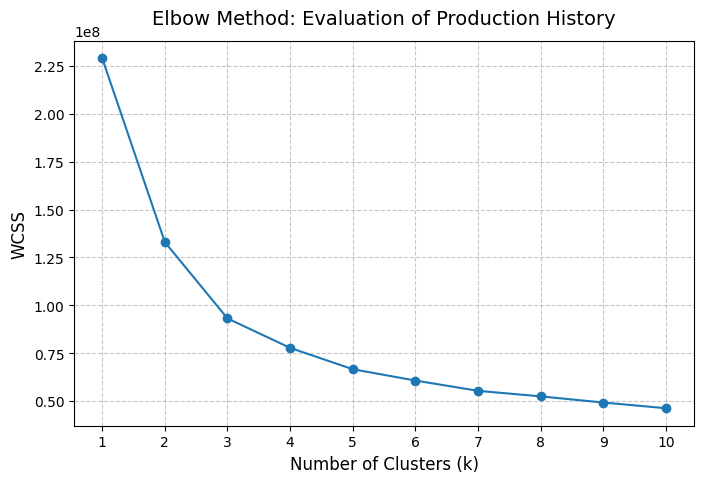

In [ ]:
# 1. Colocar o 'Nome Poço ANP' como índice e isolar apenas os dados numéricos
df_treino = prod_limpo.set_index('Nome Poço ANP').copy()

# 2. Preencher os valores nulos com 0 (K-Means falha se houver NaN)
df_treino = df_treino.fillna(0)

# 3. Executar K-Means para k de 1 a 10 e armazenar o WCSS (Inércia)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=12544292, n_init=10)
    kmeans.fit(df_treino)
    wcss.append(kmeans.inertia_)

# 4. Plotar o Gráfico do Cotovelo
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='#1f77b4')
plt.title('Elbow Method: Evaluation of Production History', fontsize=14, pad = 12)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('WCSS', fontsize=12)
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

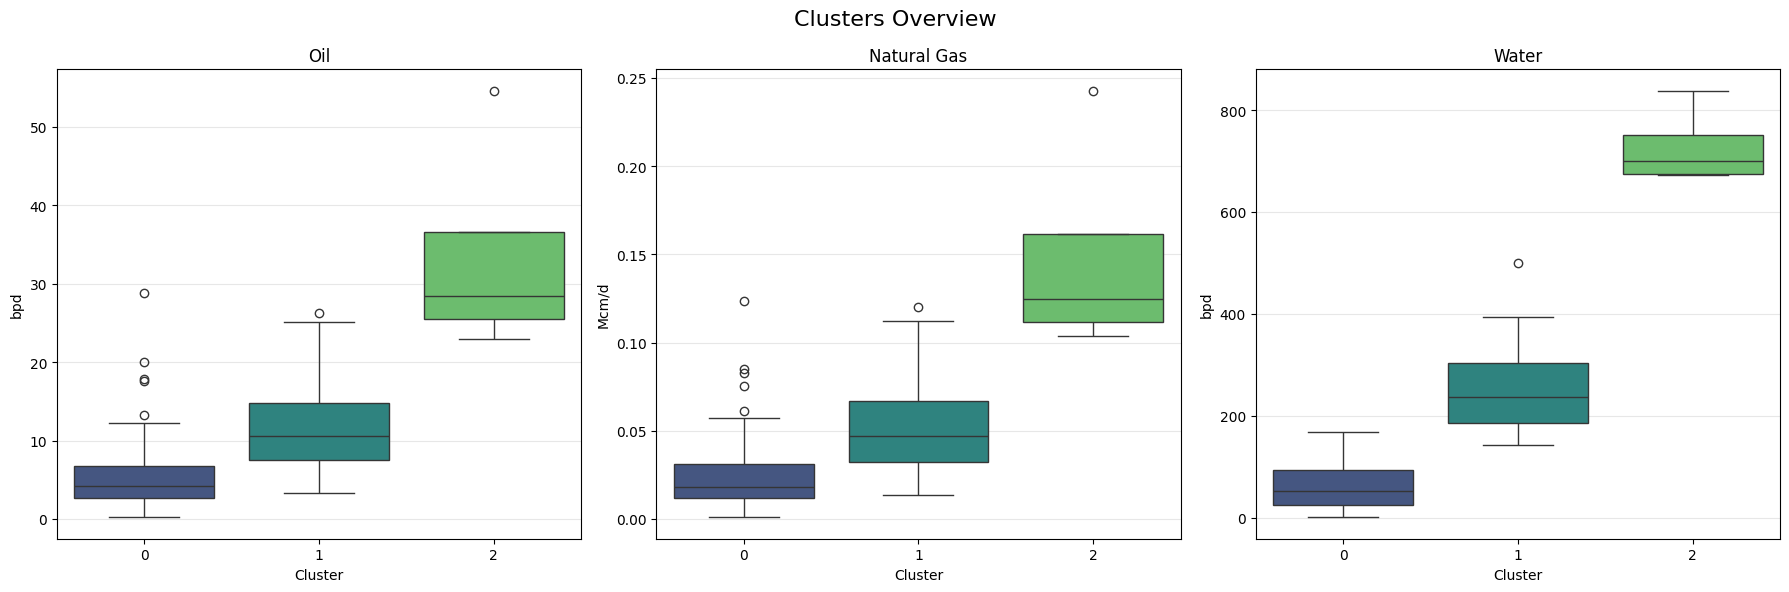

In [ ]:
# 1. Aplicar o K-Means definitivo aos dados do histórico completo
kmeans_final = KMeans(n_clusters=3, n_init=10)
df_treino['Cluster'] = kmeans_final.fit_predict(df_treino)

# 2. Transformar o Cluster em texto para melhor visualização nos gráficos
df_treino['Cluster'] = df_treino['Cluster'].astype(str)

# 3. Para visualização rápida: calcular a média de cada fluido no df_treino
# Localizamos as colunas de cada tipo para tirar a média horizontal (axis=1)
cols_oleo = [col for col in df_treino.columns if col.startswith('O_')]
cols_gas = [col for col in df_treino.columns if col.startswith('GN_')]
cols_agua = [col for col in df_treino.columns if col.startswith('A_')]

df_treino['Media_Oleo'] = df_treino[cols_oleo].mean(axis=1)
df_treino['Media_Gas'] = df_treino[cols_gas].mean(axis=1)
df_treino['Media_Agua'] = df_treino[cols_agua].mean(axis=1)

# Configurar a figura com 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Clusters Overview', fontsize=16)

# Boxplot para Petróleo
sns.boxplot(ax=axes[0], data=df_treino, x='Cluster', y='Media_Oleo', hue='Cluster', palette='viridis', legend=False)
axes[0].set_title('Oil')
axes[0].set_ylabel('bpd')
axes[0].grid(axis='y', alpha=0.3)

# Boxplot para Gás
sns.boxplot(ax=axes[1], data=df_treino, x='Cluster', y='Media_Gas', hue='Cluster', palette='viridis', legend=False)
axes[1].set_title('Natural Gas')
axes[1].set_ylabel('Mcm/d')
axes[1].grid(axis='y', alpha=0.3)

# Boxplot para Água
sns.boxplot(ax=axes[2], data=df_treino, x='Cluster', y='Media_Agua', hue='Cluster', palette='viridis', legend=False)
axes[2].set_title('Water')
axes[2].set_ylabel('bpd')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

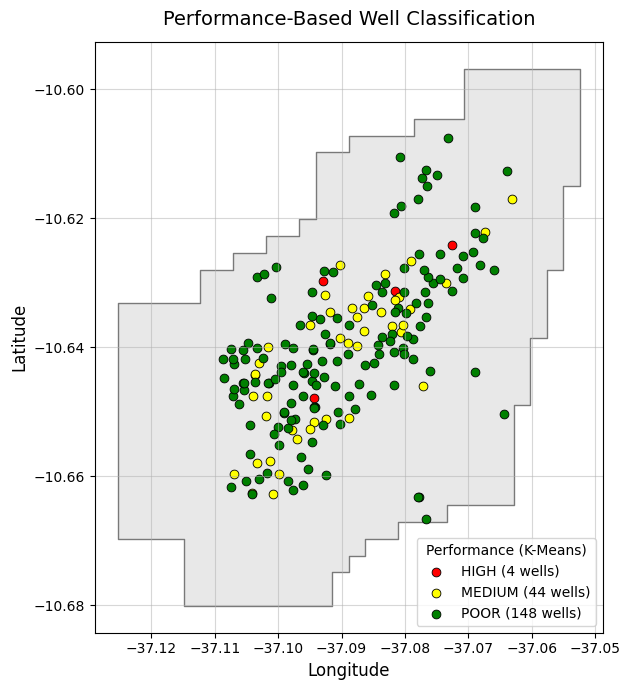

In [ ]:
import matplotlib.pyplot as plt

# 1. Preparar o df_treino
df_treino_merge = df_treino.reset_index()

# 2. Limpar os espaços em branco para garantir um merge perfeito
coluna_mapa = 'name_left' if 'name_left' in pocos_prod.columns else 'POCO'
pocos_prod[coluna_mapa] = pocos_prod[coluna_mapa].str.strip()
df_treino_merge['Nome Poço ANP'] = df_treino_merge['Nome Poço ANP'].astype(str).str.strip()

# 3. Limpar colunas antigas em pocos_prod para evitar conflitos de duplicidade
for col in ['Nome Poço ANP', 'Cluster', 'Cluster_label', 'Cluster_color']:
    if col in pocos_prod.columns:
        pocos_prod = pocos_prod.drop(columns=[col])

# 4. Fazer o Merge trazendo a coluna numérica 'Cluster' de volta
pocos_prod = pocos_prod.merge(
    df_treino_merge[['Nome Poço ANP', 'Cluster']],
    left_on=coluna_mapa,
    right_on='Nome Poço ANP',
    how='inner'
)

# 5. Criar o dicionário e aplicar o mapeamento com segurança
dic_mapeamento = {
    0: {"rotulo": "POOR", "cor": "green"},
    1: {"rotulo": "MEDIUM", "cor": "yellow"},
    2: {"rotulo": "HIGH", "cor": "red"}
}

pocos_prod['Cluster'] = pocos_prod['Cluster'].astype(int)
pocos_prod['Cluster_label'] = pocos_prod['Cluster'].map(lambda x: dic_mapeamento[x]["rotulo"])
pocos_prod['Cluster_color'] = pocos_prod['Cluster'].map(lambda x: dic_mapeamento[x]["cor"])

# 6. Plotagem final com a ordem correta e contagem na legenda
fig, ax = plt.subplots(figsize=(7 * 16 / 9, 7))

campo.plot(ax=ax, zorder=0, color="lightgray", edgecolor="black", alpha=0.5)

ordem_legenda = ["HIGH", "MEDIUM", "POOR"]

for rotulo in ordem_legenda:
    grupo = pocos_prod[pocos_prod['Cluster_label'] == rotulo]

    if not grupo.empty:
        cor = grupo['Cluster_color'].iloc[0]
        qtd_pocos = len(grupo)
        rotulo_com_contagem = f"{rotulo} ({qtd_pocos} wells)"

        grupo.plot(
            ax=ax,
            color=cor,
            label=rotulo_com_contagem,
            zorder=1,
            markersize=40,
            edgecolor='black',
            linewidth=0.6
        )

plt.title("Performance-Based Well Classification", fontsize=14, pad=12)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(title="Performance (K-Means)", loc='lower right')
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

## Análise Preliminar

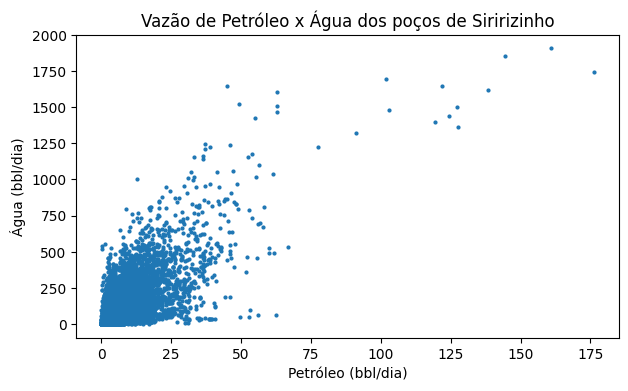

In [ ]:
plt.figure(figsize=(7,7*9/16))
plt.plot(df_melted['Petroleo_bpd'],df_melted['Agua_bpd'],'o', ms = 2)
plt.xlabel('Petróleo (bbl/dia)')
plt.ylabel('Água (bbl/dia)')
plt.title('Vazão de Petróleo x Água dos poços de Siririzinho')
plt.show()
